In [1]:
%load_ext rpy2.ipython

/Users/arturohernanzcarrasco-munoz/code/analisis_datos_series_temporales/.venv/lib/python3.9/site-packages/rpy2/ipython/rmagic.py:96: UserWarning: The Python package `pandas` is strongly recommended when using `rpy2.ipython`. Unfortunately it could not be loaded, as we did not manage to load `numpy` in the first place (error: No module named 'numpy').
  warnings.warn('The Python package `pandas` is strongly '


In [2]:
%%R
lib_loc <- "lib_loc"

In [3]:
%%R
os <- Sys.info()[["sysname"]]

Cargamos librerias

In [62]:
%%R
options (repos = c(CRAN = "https://cloud.r-project.org"))

if(!require("stats")) install.packages("stats")
library(stats, lib.loc=lib_loc)
if(!require("ggplot2")) install.packages("ggplot2")
library(ggplot2, lib.loc=lib_loc)
if(!require("ggfortify")) install.packages("ggfortify")
library(ggfortify, lib.loc=lib_loc)
if (!require("zoo", lib.loc = lib_loc)) install.packages("zoo", lib = lib_loc)
library(zoo, lib.loc = lib_loc)
if (!require("forecast", lib.loc = lib_loc)) install.packages("forecast", lib = lib_loc)
library(forecast, lib.loc = lib_loc)


Loading required package: forecast
Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 
Registered S3 methods overwritten by 'forecast':
  method                 from     
  autoplot.Arima         ggfortify
  autoplot.acf           ggfortify
  autoplot.ar            ggfortify
  autoplot.bats          ggfortify
  autoplot.decomposed.ts ggfortify
  autoplot.ets           ggfortify
  autoplot.forecast      ggfortify
  autoplot.stl           ggfortify
  autoplot.ts            ggfortify
  fitted.ar              ggfortify
  fortify.ts             ggfortify
  residuals.ar           ggfortify


# Carga del fichero

In [58]:
%%R

dfMedidas <- read.csv("AirPassengers.csv", 
                      sep = ",", dec = ".", 
                      check.names = FALSE, 
                      stringsAsFactors = TRUE, 
                      header = TRUE, 
                      fill = TRUE)

dfMedidas$año <- substr(dfMedidas$Month, 1, 4)
dfMedidas$mes <- substr(dfMedidas$Month, 6, 7)



In [59]:
%%R
head(dfMedidas)

    Month #Passengers  año mes
1 1949-01         112 1949  01
2 1949-02         118 1949  02
3 1949-03         132 1949  03
4 1949-04         129 1949  04
5 1949-05         121 1949  05
6 1949-06         135 1949  06


# Visualizamos los datos:

Visualizamos todos los valores:

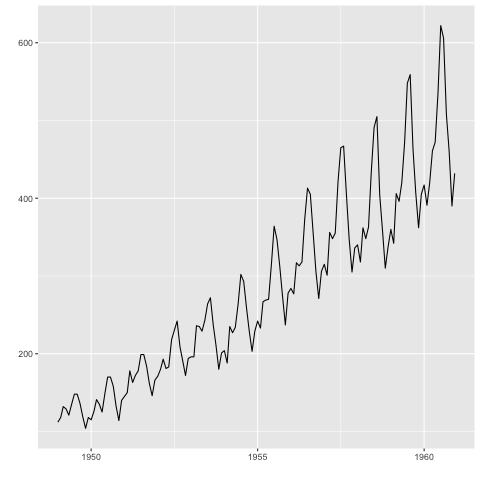

In [61]:
%%R
ts_TMED <- ts(dfMedidas$'#Passengers', frequency = 12, start = 1949) 
autoplot(ts_TMED)

Podemos ver que la distribución de los datos es ciclica cada año pero lineal en su conjunto, además, podemos ver que cada año aumenta el número de pasajeros.

# EDA:

## Distribución de los datos:

Usamos la libreria forecast para analizar las tendencias mensuales de cada año 

In addition: Warning message:
In fortify(data, ...) : Arguments in `...` must be used.
✖ Problematic argument:
• na.rm = TRUE
ℹ Did you misspell an argument name?


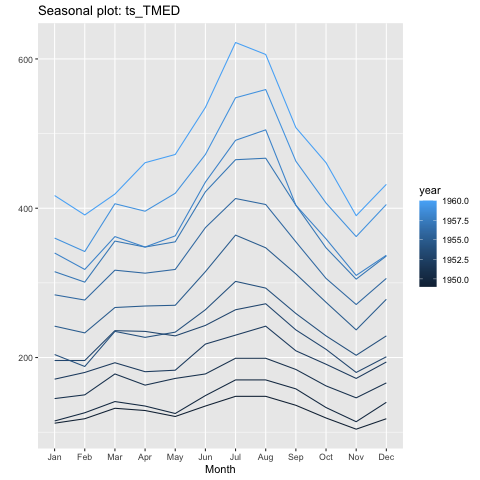

In [63]:
%%R
ggseasonplot(ts_TMED, continuous = TRUE)

In addition: Warning message:
In fortify(data, ...) : Arguments in `...` must be used.
✖ Problematic argument:
• na.rm = TRUE
ℹ Did you misspell an argument name?


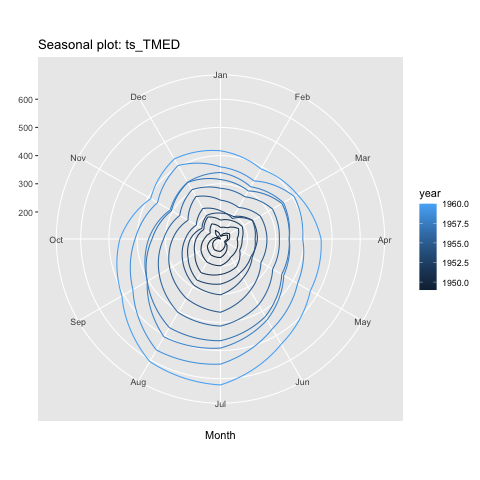

In [64]:
%%R
ggseasonplot(ts_TMED, continuous = TRUE, polar=TRUE)

In addition: Warning message:
In fortify(data, ...) : Arguments in `...` must be used.
✖ Problematic argument:
• na.rm = TRUE
ℹ Did you misspell an argument name?


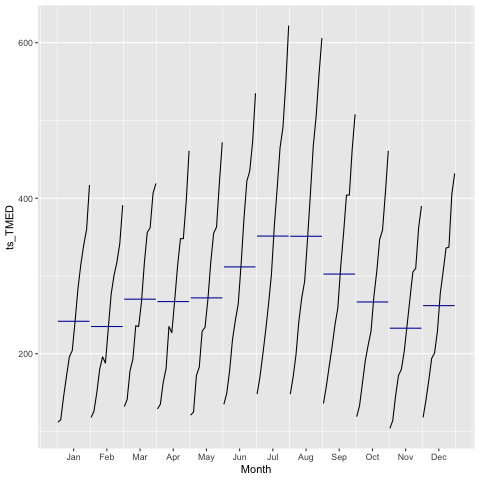

In [65]:
%%R
ggsubseriesplot(ts_TMED)

Las 2 primeras gráficas muestran el número de pasajeros por año con una línea de tonalidad azul (cuanto más antiguo es el año, más oscuro es el color), mientras que la última gráfica muestra la misma información pero centrandose en los meses y no en los años, es decir, agrupa el número de pasajeros de cada mes en una línea de tendencia vertical.

Como hemos visto anteriormente, cada año el número de pasajeros aumenta. 
Como novedad aportada por estas gráfica podemos ver las tendencias por mes:
Se puede comprobar un aumento del número de viajes en avión en los meses de verano (finales de mayo a septiembre), con el mayor número en los meses de julio y agosto.
Es curioso como estos picos se van alternando cada pocos años, cada 2/3 años julio y agosto se turnan el liderzgo de más viajeros por mes.

A la hora de discutir la frecuencia correcta de los datos, usamos la siguiente gráfica, que muestra la distribución de un dato en el instante t frente a otro en el instante t-lag(n). 

El punto de mayor correlación mostrará la frecuencia correcta.

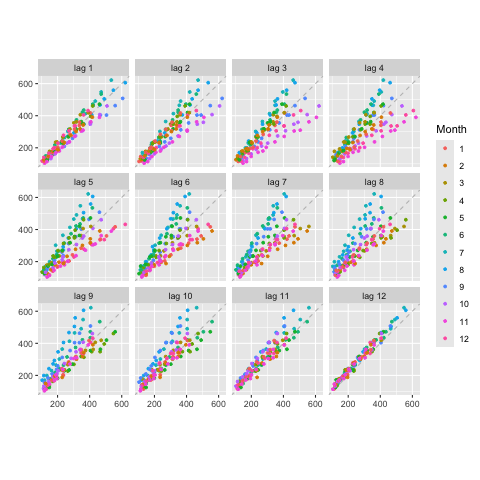

In [66]:
%%R
gglagplot(ts_TMED, do.lines = FALSE, lags = 12) + geom_point(size = 0.1, stroke = 0)

Efectivamente, la frecuencia es de 12 meses.

## Correlación de los datos:

Evaluamos la autocorrelación de la serie:

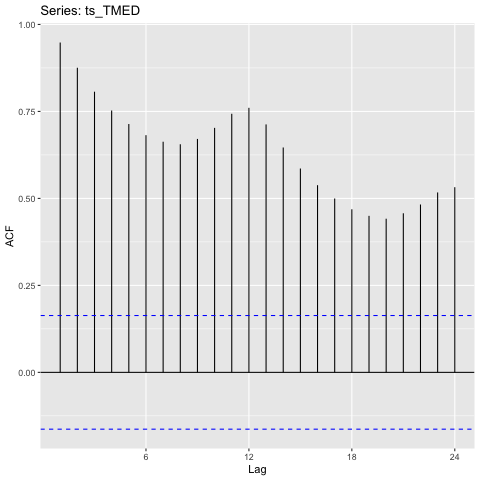

In [67]:
%%R
ggAcf(ts_TMED)

En esta gráfica podemos ver una clara tendencia, pues la correlación disminuye poco a poco conforme comparamos con valores lejanos, de lo que se puede deducir que la serie no es estacionaria.

Por otro lado, podemos ver que el menor valor de ACF es, más o menos, 0.4 (para lag = 20), esto nos indica la alta correlación.

Por último, el claro patrón de tendencias cada 12 meses nos indica el carácter estacional de la venta de billetes de avión.

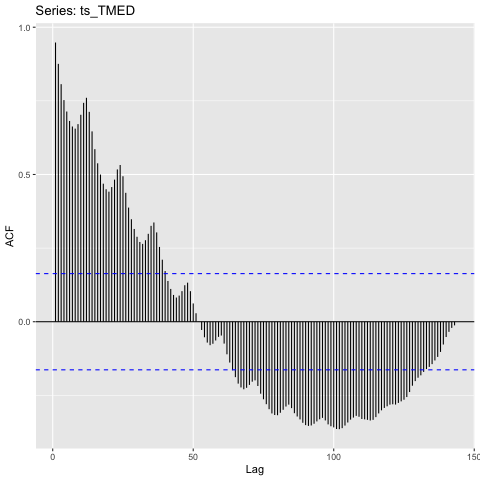

In [71]:
%%R
ggAcf(ts_TMED, lag = 145)

De esta segunda gráfica de ACF podemos ver que con un lag > 50 los valores son tan diferentes dentro de la tendencia creciente que el valor de ACF se vuelve negativo.

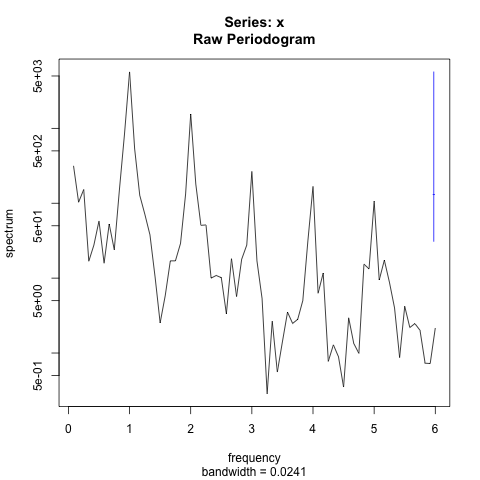

In [68]:
%%R
spectrum(ts_TMED)

Aunque hay presencia de ruido en esta gráfica, podemos ver que la periodicidad es, de nuevo, 12 meses

Después de analizar las diferentes gráficas podemos ver que la serie presenta una tendencia fuerte y no lineal, además, la estacionalidad está muy marcada, aumentando la cantidad de vuelos cada año (serie multiplicativa), la varianza es creciente y la serie no es estacionaria.

Todo esto esto habrá que tenerlo en cuenta a la hora de probar los algoritmos Holt-Winters, ARIMA y TBATS.
* Holt-Winters: Puede dar problemas una tendencia no lineal.
* ARIMA: Requiere una serie estacionaria (o convertirla) y que la tendencia sea lineal.
* TBATS: Funciona bien con una estacionalidad no lineal o cambiante y con tendencias complejas.

## Descomposición de la serie

Descomponemos la serie multiplicativa para separar las diferentes tendencias dentro de la misma.

### Descomposición Multiplicativa

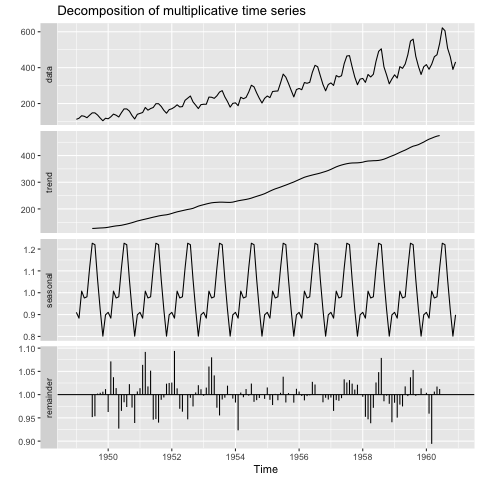

In [73]:
%%R
ts_TMED_desc <- decompose(ts_TMED, type = "multiplicative")
autoplot(ts_TMED_desc)

Aquí podemos observar un incremento lineal de los pasajeros a lo largo del tiempo, así como una estacionalidad marcada en verano.
Además, hay una disminución de los residuos a mediados de la serie, esto se debe a como se calculan estos valores, pues tanto al principio como al final no se disponen de los datos suficientes como para calcular de manera precisa los residuos.

### Descomposición con regresión local (LOESS)

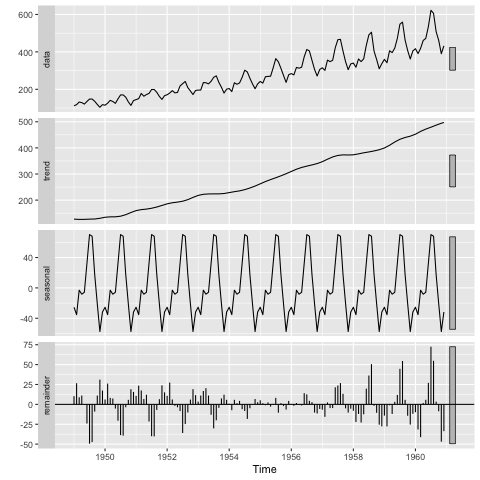

In [74]:
%%R
ts_TMED_stl <- stl(ts_TMED, s.window = "periodic")
autoplot(ts_TMED_stl)

Este segundo método es peor a la hora de detectar los residuos (gran variación al principio y final), por lo que se mantiene la descomposición multiplicativa.

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


R callback write-console: In addition:   
R callback write-console: Warning messages:
  
R callback write-console: 1: Removed 12 rows containing non-finite outside the scale range
(`stat_smooth()`). 
  
R callback write-console: 2: Removed 12 rows containing non-finite outside the scale range
(`stat_smooth()`). 
  


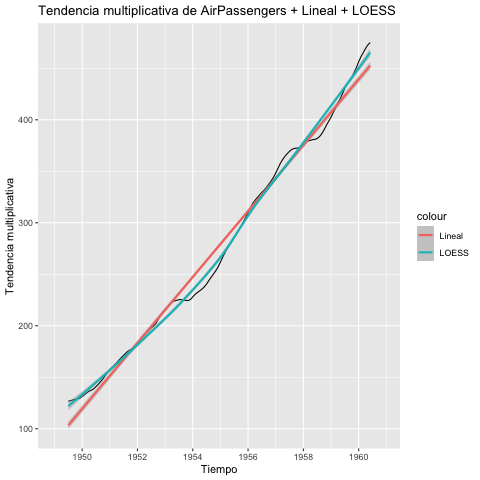

In [76]:
%%R
ts_AP_desc_mult <- decompose(ts_AP, type = "multiplicative")

trend_mult <- ts_AP_desc_mult$trend

autoplot(trend_mult) +
  stat_smooth(method = "lm", aes(color = "Lineal"), se = TRUE) +
  stat_smooth(method = "loess", aes(color = "LOESS"), se = TRUE) +
  ggtitle("Tendencia multiplicativa de AirPassengers + Lineal + LOESS") +
  xlab("Tiempo") + ylab("Tendencia multiplicativa")

Una vez descompuestas las tendencias de la serie usando el método multiplicativo, podemos ver que LOESS se aproxima mejor a la hora de suavizar y estimar la tendencia que una regresión lineal. 

# Modelos

## Holt-Winters

## ARIMA

## TBATS